# Taxi Lab 2 — NumPy and scikit-learn

A more realistic fare: a rate per kilometre **and** a pickup fee (the flag fall).

Model: `price = w * km + b`. True values: **w = 1.50**, **b = 2.00**. Learning rate: **0.01**, 2000 steps.

We run gradient descent in NumPy, then compare with `sklearn.linear_model.LinearRegression`.

Walkthrough on the wiki: [https://ml.albertprofe.dev/foundations/mlab01-2.html](https://ml.albertprofe.dev/foundations/mlab01-2.html)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/AlbertProfe/wikiml-labs/blob/taxi-lab/taxi/taxi_lab_2_numpy_sklearn.ipynb)
[Code on GitHub](https://github.com/AlbertProfe/wikiml-labs/blob/taxi-lab/taxi/taxi_lab_2_numpy_sklearn.ipynb)


## More receipts, and a base fare

Eight rides, generated from `price = 1.5 · km + 2`. The program is not told those two numbers.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.linear_model import LinearRegression

km = np.array([1.0, 2.0, 3.0, 5.0, 6.0, 8.0, 10.0, 12.0])
price = np.array([3.50, 5.00, 6.50, 9.50, 11.00, 14.00, 17.00, 20.00])

print("Receipts:")
for x, y in zip(km, price):
    print(f"  {x:4.0f} km   €{y:.2f}")

Receipts:
     1 km   €3.50
     2 km   €5.00
     3 km   €6.50
     5 km   €9.50
     6 km   €11.00
     8 km   €14.00
    10 km   €17.00
    12 km   €20.00


## Gradient descent for *w* and *b*

The loop is the same as Lab 1, with one extra gradient: the derivative of the mean squared error with respect to `b` is the average of `2 * error`.

In [2]:
w = 0.0
b = 0.0
learning_rate = 0.01
steps = 2000
show_at = {0, 1, 5, 10, 50, 100, 200, 500, 1000, 2000}

history_w = [w]
history_b = [b]
history_loss = []

pred = w * km + b
loss = float(np.mean((pred - price) ** 2))
history_loss.append(loss)

print("After step |        w |        b |     loss")
print("-----------+----------+----------+---------")
print(f"     start | {w:8.4f} | {b:8.4f} | {loss:7.4f}")

for step in range(1, steps + 1):
    pred = w * km + b
    err = pred - price
    grad_w = float(np.mean(2 * err * km))
    grad_b = float(np.mean(2 * err))
    w = w - learning_rate * grad_w
    b = b - learning_rate * grad_b
    pred = w * km + b
    loss = float(np.mean((pred - price) ** 2))
    history_w.append(w)
    history_b.append(b)
    history_loss.append(loss)
    if step in show_at:
        print(f"{step:10d} | {w:8.4f} | {b:8.4f} | {loss:7.4f}")

print(f"\nGradient descent:  w = {w:.6f}   b = {b:.6f}")

After step |        w |        b |     loss
-----------+----------+----------+---------
     start |   0.0000 |   0.0000 | 146.9688
         1 |   1.6713 |   0.2162 |  0.9965
         5 |   1.7146 |   0.2610 |  0.8440
        10 |   1.7088 |   0.3083 |  0.7987
        50 |   1.6675 |   0.6430 |  0.5139
       100 |   1.6271 |   0.9699 |  0.2961
       200 |   1.5733 |   1.4065 |  0.0983
       500 |   1.5140 |   1.8865 |  0.0036
      1000 |   1.5009 |   1.9928 |  0.0000
      2000 |   1.5000 |   2.0000 |  0.0000

Gradient descent:  w = 1.500004   b = 1.999971


## Compare with scikit-learn

`LinearRegression` solves the same least-squares problem in closed form. On clean receipts it should land on the true `w` and `b`.

In [3]:
model = LinearRegression()
model.fit(km.reshape(-1, 1), price)
sk_w = float(model.coef_[0])
sk_b = float(model.intercept_)
print(f"LinearRegression:  w = {sk_w:.6f}   b = {sk_b:.6f}")
print(f"True values:       w = 1.500000   b = 2.000000")

LinearRegression:  w = 1.500000   b = 2.000000
True values:       w = 1.500000   b = 2.000000


Two parameters take more steps than one. After 500 steps the fit is already close; after 2000 steps gradient descent matches scikit-learn.

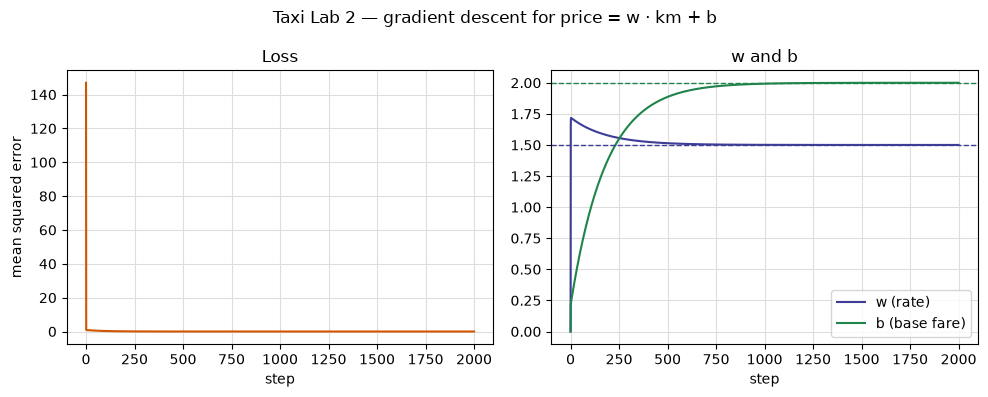

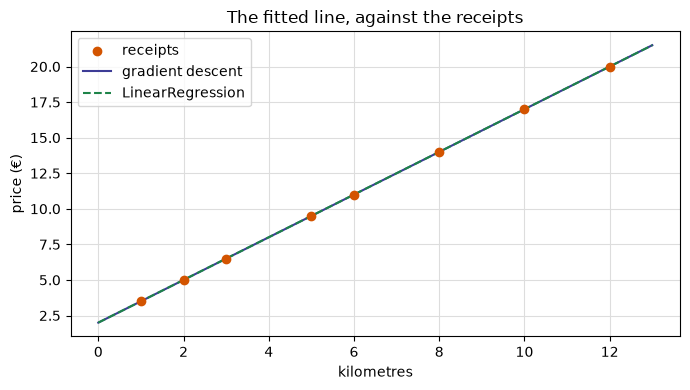

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(history_loss, color="#d35400")
axes[0].set_xlabel("step")
axes[0].set_ylabel("mean squared error")
axes[0].set_title("Loss")
axes[0].grid(True, color="#dddddd")

axes[1].plot(history_w, color="#3d3c96", label="w (rate)")
axes[1].plot(history_b, color="#1e8449", label="b (base fare)")
axes[1].axhline(1.5, color="#3d3c96", linestyle="--", linewidth=1)
axes[1].axhline(2.0, color="#1e8449", linestyle="--", linewidth=1)
axes[1].set_xlabel("step")
axes[1].set_title("w and b")
axes[1].legend()
axes[1].grid(True, color="#dddddd")
fig.suptitle("Taxi Lab 2 — gradient descent for price = w · km + b")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
xs = np.linspace(0, 13, 50)
ax.scatter(km, price, color="#d35400", zorder=3, label="receipts")
ax.plot(xs, w * xs + b, color="#3d3c96", label="gradient descent")
ax.plot(xs, sk_w * xs + sk_b, color="#1e8449", linestyle="--", label="LinearRegression")
ax.set_xlabel("kilometres")
ax.set_ylabel("price (€)")
ax.set_title("The fitted line, against the receipts")
ax.legend()
ax.grid(True, color="#dddddd")
fig.tight_layout()
plt.show()